In [1]:
name = 'Xasanov Temur'
print(name)

Xasanov Temur


In [2]:
import  pandas as pd
import numpy as np
import  matplotlib.pyplot as plt
from matplotlib import ticker
import seaborn as sns
import  zlib
ISM = "Xasanov Temur"

CSV_YOL = "data/data.csv"

def imzo():
    plt.figtext(0.99, 0.01, ISM, ha="right", fontsize=8, color="gray")

def k_formatter():
    """Y o'qidagi sonlarni 1000000 -> 1000k ko'rinishiga keltiradi."""
    return ticker.FuncFormatter(lambda x, _: f"{x/1000:.0f}k")

def shaxsiy_jadval_yarat():
    np.random.seed(zlib.crc32(ISM.encode()))
    sanalar = pd.date_range("2025-01-01", "2025-12-31", freq="D")
    toifalar = ["Elektronika", "Kiyim", "Kitob"]
    n = len(sanalar)
    t = np.repeat(np.arange(3), n)
    kun = np.tile(np.arange(n), 3)

    asos = np.random.randint(250, 451, 3)
    trend = np.random.uniform(-0.4, 0.6, 3)
    pik = np.random.randint(0, 365, 3)
    mavsum = np.random.randint(30, 121, 3)
    shovqin = np.random.randint(15, 61, 3)

    savdo = (asos[t] + trend[t] * kun
             + mavsum[t] * np.cos(2 * np.pi * (kun - pik[t]) / 365)
             + np.random.normal(0, 1, 3 * n) * shovqin[t])

    aksiya = np.random.rand(3 * n) < 0.02
    savdo[aksiya] = savdo[aksiya] * np.random.uniform(2, 3.5, aksiya.sum())

    return pd.DataFrame({
        "sana": np.tile(sanalar, 3),
        "toifa": np.repeat(toifalar, n),
        "savdo": savdo.clip(min=20).round(),
    })


def oylik_shaxsiy(df):
    return df.pivot_table(index=pd.Grouper(key="sana", freq="MS"),
                          columns="toifa", values="savdo", aggfunc="sum")

def retail_yukla(yol=CSV_YOL):
    df = pd.read_csv(yol, encoding='latin-1')
    df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
    if "summa" not in df.columns:
        df["summa"] = df["Quantity"] * df["UnitPrice"]
    return df

def oylik_daromad(retail):
    return retail.set_index("InvoiceDate")["summa"].resample("MS").sum()

df = shaxsiy_jadval_yarat()
retail = retail_yukla()
print("Ism:",ISM)
print("Shaxsiy jadval:", df.shape, "| Retail:", retail.shape)
print(df.head(4))
print(retail.head(4))

Ism: Xasanov Temur
Shaxsiy jadval: (1095, 3) | Retail: (541909, 9)
        sana        toifa  savdo
0 2025-01-01  Elektronika  354.0
1 2025-01-02  Elektronika  399.0
2 2025-01-03  Elektronika  404.0
3 2025-01-04  Elektronika  353.0
  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   

          InvoiceDate  UnitPrice  CustomerID         Country  summa  
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom  15.30  
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  20.34  
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom  22.00  
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  20.34  


Talaba: Xasanov Temur
shape: (1095, 3)
        sana        toifa  savdo
0 2025-01-01  Elektronika  354.0
1 2025-01-02  Elektronika  399.0
2 2025-01-03  Elektronika  404.0
3 2025-01-04  Elektronika  353.0
4 2025-01-05  Elektronika  406.0

Oylik jami savdo:
 toifa       Elektronika    Kitob    Kiyim
sana                                     
2025-01-01      12574.0  15841.0   9221.0
2025-02-01      11133.0  13710.0   8425.0
2025-03-01      12485.0  14079.0   7262.0
2025-04-01      13177.0  14297.0   6812.0
2025-05-01      11385.0  11711.0   7008.0
2025-06-01      11526.0  10306.0   7736.0
2025-07-01      11270.0  10322.0   8869.0
2025-08-01      10857.0  10628.0  11891.0
2025-09-01      11464.0  10812.0  11404.0
2025-10-01      12238.0  11817.0  11514.0
2025-11-01      12410.0  12202.0  11084.0
2025-12-01      12976.0  12824.0  10688.0


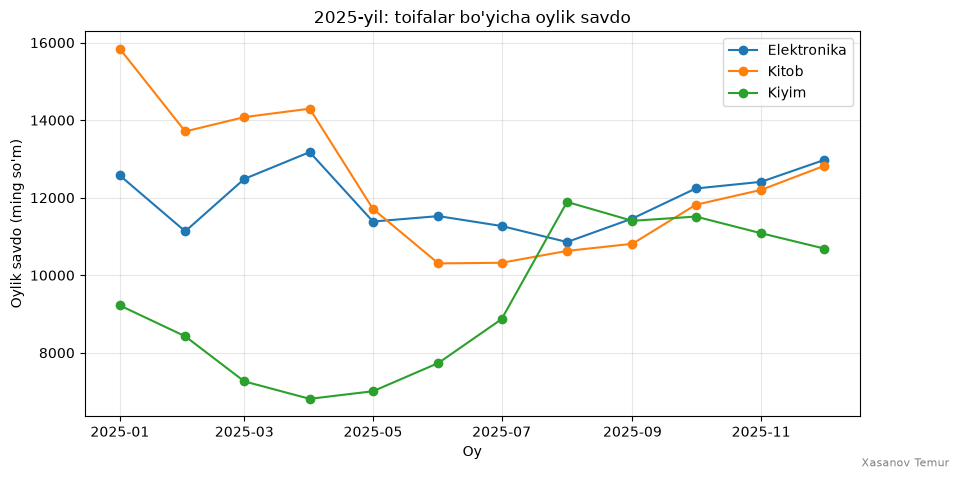


Yanvar va dekabr:
Elektronika: yanvar=12574, dekabr=12976 -> O`SDI
Kitob: yanvar=15841, dekabr=12824 -> PASAYDI
Kiyim: yanvar=9221, dekabr=10688 -> O`SDI

Eng yuqori oy (idxmax):
toifa
Elektronika   2025-04-01
Kitob         2025-01-01
Kiyim         2025-08-01
dtype: datetime64[us]


In [3]:
def t1_1(df):
        print("Talaba:", ISM)
        print("shape:", df.shape)
        print(df.head())

        oylik = oylik_shaxsiy(df)
        print("\nOylik jami savdo:\n", oylik)

        fig, ax = plt.subplots(figsize=(10, 5))
        for toifa in oylik.columns:
            ax.plot(oylik.index, oylik[toifa], marker="o", label=toifa)
        ax.set_title("2025-yil: toifalar bo'yicha oylik savdo")
        ax.set_xlabel("Oy")
        ax.set_ylabel("Oylik savdo (ming so'm)")
        ax.legend()
        ax.grid(True, alpha=0.3)
        imzo()
        plt.show()
        print("\nYanvar va dekabr:")
        for toifa in oylik.columns:
            yan, dek = oylik[toifa].iloc[0], oylik[toifa].iloc[-1]
            print(f"{toifa}: yanvar={yan:.0f}, dekabr={dek:.0f} -> "
                  f"{'O`SDI' if dek > yan else 'PASAYDI'}")

        print("\nEng yuqori oy (idxmax):")
        print(oylik.idxmax())

t1_1(df)

Talaba: Xasanov Temur


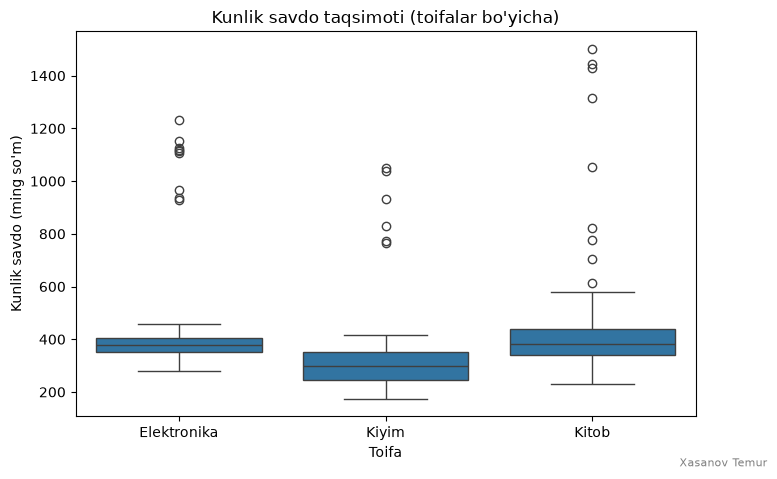

             count        mean         std    min    25%    50%    75%     max
toifa                                                                         
Elektronika  365.0  393.136986  114.994280  281.0  352.0  379.0  404.0  1232.0
Kitob        365.0  406.983562  137.950321  230.0  341.0  381.0  440.0  1502.0
Kiyim        365.0  306.613699   96.490627  174.0  246.0  299.0  352.0  1050.0

                 Q1     Q3    IQR   quyi  yuqori  outlier_soni  median
toifa                                                                
Elektronika  352.0  404.0   52.0  274.0   482.0             9   379.0
Kitob        341.0  440.0   99.0  192.5   588.5             9   381.0
Kiyim        246.0  352.0  106.0   87.0   511.0             6   299.0

Medianasi eng yuqori: Kitob
IQR eng katta: Kiyim


In [4]:
def t1_2(df):
    print("Talaba:", ISM)
    fig, ax = plt.subplots(figsize=(8, 5))
    sns.boxplot(data=df, x="toifa", y="savdo", ax=ax)
    ax.set_title("Kunlik savdo taqsimoti (toifalar bo'yicha)")
    ax.set_xlabel("Toifa")
    ax.set_ylabel("Kunlik savdo (ming so'm)")
    imzo()
    plt.show()
    print(df.groupby("toifa")["savdo"].describe())
    q = df.groupby("toifa")["savdo"].quantile([0.25, 0.75]).unstack()
    q.columns = ["Q1", "Q3"]
    q["IQR"] = q["Q3"] - q["Q1"]
    q["quyi"] = q["Q1"] - 1.5 * q["IQR"]
    q["yuqori"] = q["Q3"] + 1.5 * q["IQR"]
    outlier = []
    for toifa, guruh in df.groupby("toifa"):
        s = guruh["savdo"]
        outlier.append(((s < q.loc[toifa, "quyi"]) | (s > q.loc[toifa, "yuqori"])).sum())
    q["outlier_soni"] = outlier
    q["median"] = df.groupby("toifa")["savdo"].median()
    print("\n", q.round(1))
    print("\nMedianasi eng yuqori:", q["median"].idxmax())
    print("IQR eng katta:", q["IQR"].idxmax())

t1_2(df)

Talaba: Xasanov Temur
Eng kichik sana: 2010-12-01 08:26:00
Eng katta sana:  2011-12-09 12:50:00

Oylik daromad (£):
 InvoiceDate
2010-12-01     748957.0
2011-01-01     560000.0
2011-02-01     498063.0
2011-03-01     683267.0
2011-04-01     493207.0
2011-05-01     723334.0
2011-06-01     691123.0
2011-07-01     681300.0
2011-08-01     682681.0
2011-09-01    1019688.0
2011-10-01    1070705.0
2011-11-01    1461756.0
2011-12-01     433668.0
Freq: MS, Name: summa, dtype: float64


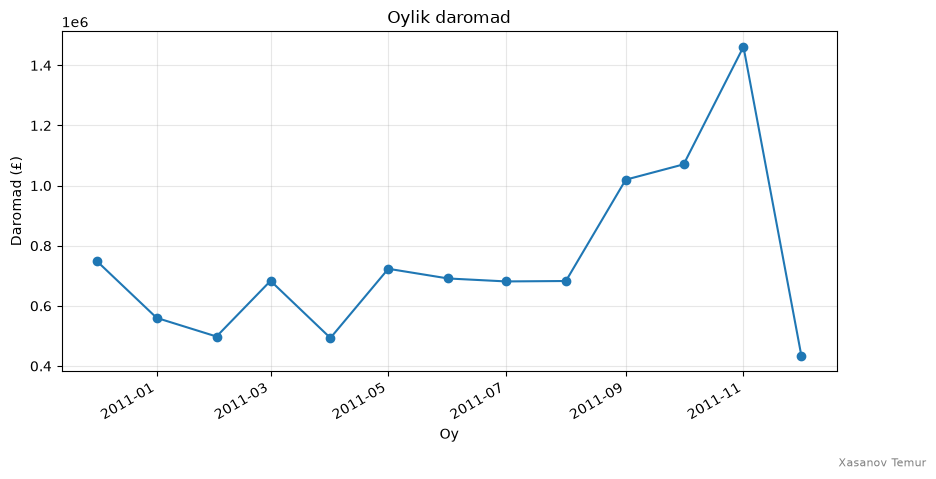


Eng yuqori oy: 2011-11 — £1,461,756
Eng past oy:   2011-12 — £433,668


In [5]:
def t2_1(retail):
    print("Talaba:", ISM)
    print("Eng kichik sana:", retail["InvoiceDate"].min())
    print("Eng katta sana: ", retail["InvoiceDate"].max())

    oylik = oylik_daromad(retail)
    print("\nOylik daromad (£):\n", oylik.round(0))

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(oylik.index, oylik.values, marker="o")
    ax.set_title("Oylik daromad")
    ax.set_xlabel("Oy")
    ax.set_ylabel("Daromad (£)")
    ax.grid(True, alpha=0.3)
    fig.autofmt_xdate()
    imzo()
    plt.show()

    print(f"\nEng yuqori oy: {oylik.idxmax():%Y-%m} — £{oylik.max():,.0f}")
    print(f"Eng past oy:   {oylik.idxmin():%Y-%m} — £{oylik.min():,.0f}")


t2_1(retail)

Talaba: Xasanov Temur


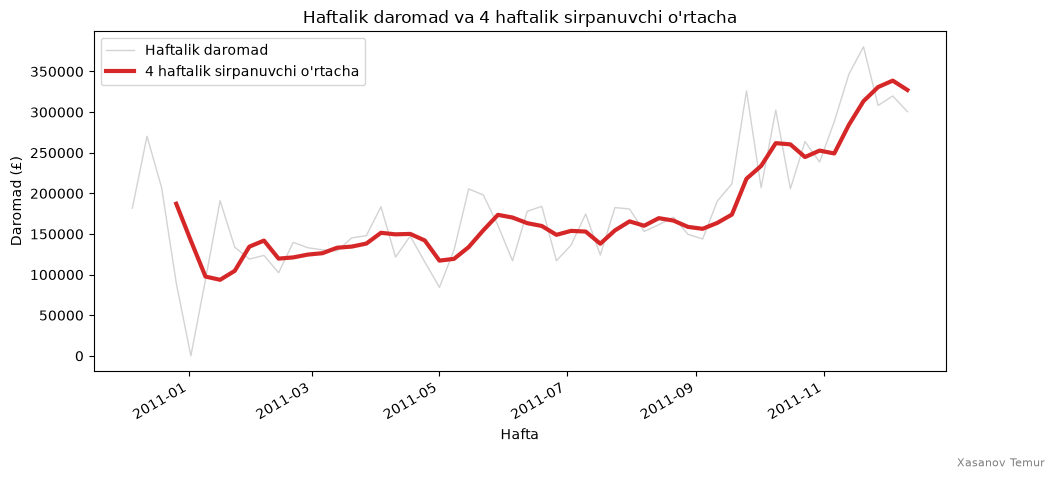

Eng past hafta: 2011-01-02 — £0


In [6]:
def t2_2(retail):
    print("Talaba:", ISM)
    haftalik = retail.set_index("InvoiceDate")["summa"].resample("W").sum()
    sirpanuvchi = haftalik.rolling(4).mean()

    fig, ax = plt.subplots(figsize=(11, 5))
    ax.plot(haftalik.index, haftalik.values, color="lightgray",
            linewidth=1, label="Haftalik daromad")
    ax.plot(sirpanuvchi.index, sirpanuvchi.values, color="tab:red",
            linewidth=3, label="4 haftalik sirpanuvchi o'rtacha")
    ax.set_title("Haftalik daromad va 4 haftalik sirpanuvchi o'rtacha")
    ax.set_xlabel("Hafta")
    ax.set_ylabel("Daromad (£)")
    ax.legend()
    fig.autofmt_xdate()
    imzo()
    plt.show()

    print(f"Eng past hafta: {haftalik.idxmin():%Y-%m-%d} — £{haftalik.min():,.0f}")


t2_2(retail)

Talaba: Xasanov Temur
Buyurtmalar soni bo'yicha top-5:
 Country
United Kingdom    23494
Germany             603
France              461
EIRE                360
Belgium             119
Name: count, dtype: int64


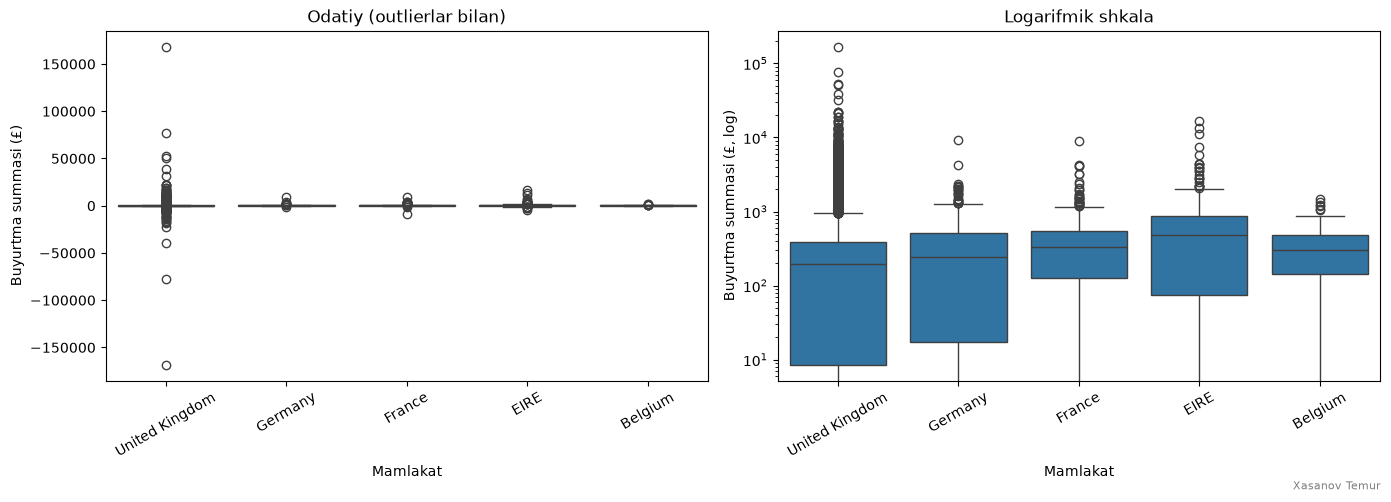


                 buyurtmalar_soni  median  ortacha
Country                                          
United Kingdom             23494  198.27   348.51
Germany                      603  246.54   367.66
France                       461  327.23   428.21
EIRE                         360  484.38   731.32
Belgium                      119  300.76   343.79

Medianasi eng katta mamlakat: EIRE


In [7]:
def t2_3(retail):
    print("Talaba:", ISM)
    buyurtma = retail.groupby("InvoiceNo").agg(summa=("summa", "sum"),
                                               Country=("Country", "first"))
    top5 = buyurtma["Country"].value_counts().head(5)
    print("Buyurtmalar soni bo'yicha top-5:\n", top5)

    data = buyurtma[buyurtma["Country"].isin(top5.index)]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    sns.boxplot(data=data, x="Country", y="summa", order=top5.index, ax=ax1)
    ax1.set_title("Odatiy (outlierlar bilan)")
    ax1.set_xlabel("Mamlakat")
    ax1.set_ylabel("Buyurtma summasi (£)")

    sns.boxplot(data=data, x="Country", y="summa", order=top5.index, ax=ax2)
    ax2.set_yscale("log")
    ax2.set_title("Logarifmik shkala")
    ax2.set_xlabel("Mamlakat")
    ax2.set_ylabel("Buyurtma summasi (£, log)")
    for ax in (ax1, ax2):
        ax.tick_params(axis="x", rotation=30)
    plt.tight_layout()
    imzo()
    plt.show()
    jadval = (data.groupby("Country")["summa"]
              .agg(["count", "median", "mean"])
              .loc[top5.index].round(2))
    jadval.columns = ["buyurtmalar_soni", "median", "ortacha"]
    print("\n", jadval)
    print("\nMedianasi eng katta mamlakat:", jadval["median"].idxmax())


t2_3(retail)

Talaba: Xasanov Temur


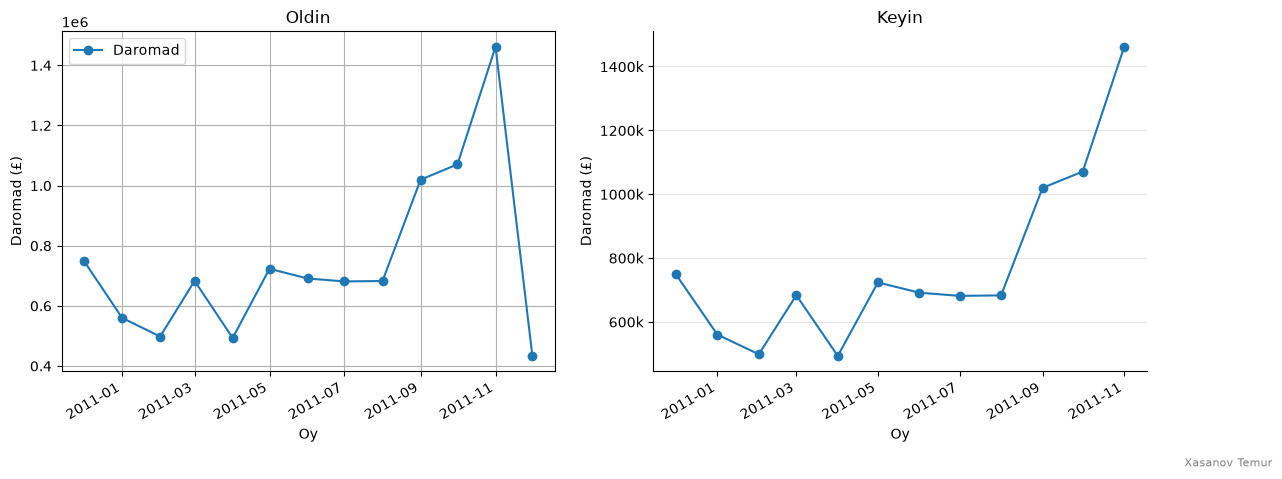

In [8]:
def t3_1(retail):
    print("Talaba:", ISM)
    oylik = oylik_daromad(retail)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    ax1.plot(oylik.index, oylik.values, marker="o", label="Daromad")
    ax1.set_title("Oldin")
    ax1.set_xlabel("Oy")
    ax1.set_ylabel("Daromad (£)")
    ax1.grid(True)
    ax1.legend()
    toza = oylik.iloc[:-1]
    ax2.plot(toza.index, toza.values, marker="o")
    ax2.set_title("Keyin")
    ax2.set_xlabel("Oy")
    ax2.set_ylabel("Daromad (£)")
    ax2.spines[["top", "right"]].set_visible(False)
    ax2.grid(axis="y", alpha=0.3)
    ax2.yaxis.set_major_formatter(k_formatter())

    fig.autofmt_xdate()
    imzo()
    plt.show()


t3_1(retail)

Talaba: Xasanov Temur
Dekabr ÷ Yanvar:
 toifa
Elektronika    1.03
Kitob          0.81
Kiyim          1.16
dtype: float64
Eng ko'p o'sgan toifa: Kiyim
RANG: {'Elektronika': '#B0B0B0', 'Kitob': '#B0B0B0', 'Kiyim': '#D1495B'}


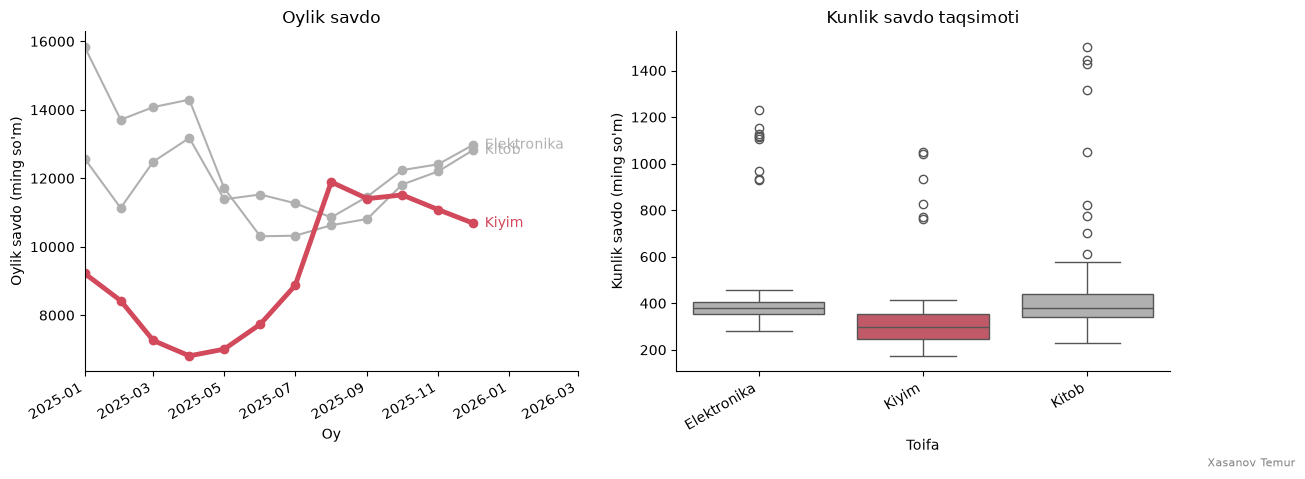

In [9]:
def t3_2(df):
    print("Talaba:", ISM)
    oylik = oylik_shaxsiy(df)
    nisbat = oylik.iloc[-1] / oylik.iloc[0]
    print("Dekabr ÷ Yanvar:\n", nisbat.round(2))
    eng_osgan = nisbat.idxmax()
    print("Eng ko'p o'sgan toifa:", eng_osgan)

    RANG = {t: "#B0B0B0" for t in oylik.columns}
    RANG[eng_osgan] = "#D1495B"
    print("RANG:", RANG)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    for toifa in oylik.columns:
        qalin = 3.5 if toifa == eng_osgan else 1.5
        ax1.plot(oylik.index, oylik[toifa], color=RANG[toifa], linewidth=qalin, marker="o")
        ax1.text(oylik.index[-1] + pd.Timedelta(days=10), oylik[toifa].iloc[-1],
                 toifa, color=RANG[toifa], va="center")
    ax1.set_xlim(oylik.index[0], oylik.index[-1] + pd.Timedelta(days=90))
    ax1.set_title("Oylik savdo")
    ax1.set_xlabel("Oy")
    ax1.set_ylabel("Oylik savdo (ming so'm)")
    a
    sns.boxplot(data=df, x="toifa", y="savdo", hue="toifa",
                palette=RANG, legend=False, ax=ax2)
    ax2.set_title("Kunlik savdo taqsimoti")
    ax2.set_xlabel("Toifa")
    ax2.set_ylabel("Kunlik savdo (ming so'm)")
    ax2.spines[["top", "right"]].set_visible(False)

    fig.autofmt_xdate()
    imzo()
    plt.show()
    return RANG


RANG = t3_2(df)

Talaba: Xasanov Temur


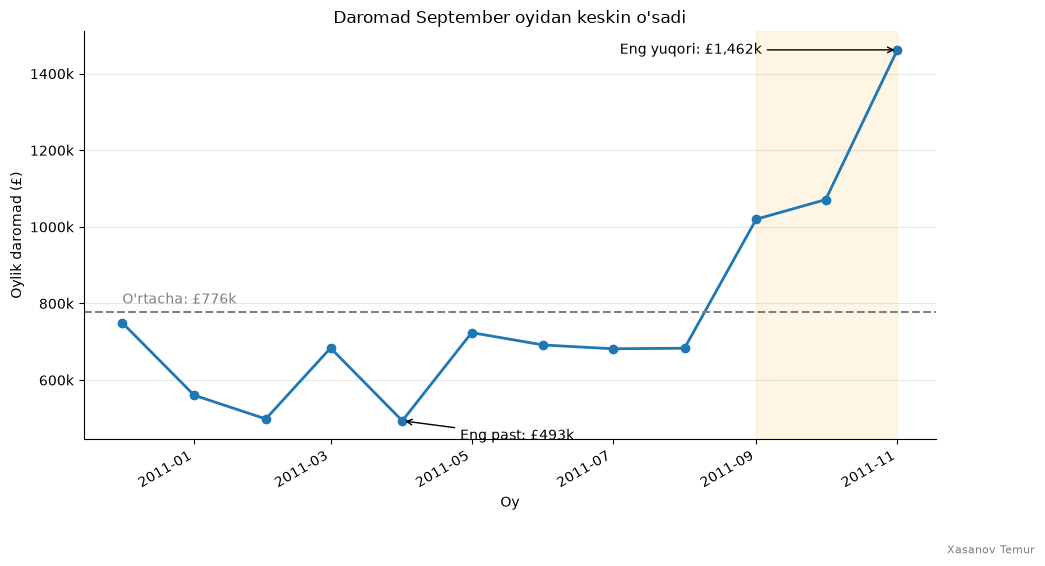

Keskin o'sish boshlangan oy: 2011-09
Sep–noyabr daromadi: £3,552,149
Yillik daromad (Dek-2010 … Noy-2011): £9,314,080
Ulush: 38.1%


In [10]:
def t3_3(retail, boshlanish=None):
    print("Talaba:", ISM)
    oylik = oylik_daromad(retail).iloc[:-1]    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    eng_yuqori, eng_past = oylik.idxmax(), oylik.idxmin()
    ortacha = oylik.mean()
    if boshlanish is None:
        osish = oylik.pct_change()
        boshlanish = osish[osish.index >= "2011-07-01"].idxmax()
    boshlanish = pd.Timestamp(boshlanish)
    oxiri = oylik.index[-1]
    fig, ax = plt.subplots(figsize=(11, 6))
    ax.plot(oylik.index, oylik.values, marker="o", linewidth=2)
    ax.annotate(f"Eng yuqori: £{oylik.max()/1000:,.0f}k",
                xy=(eng_yuqori, oylik.max()),
                xytext=(eng_yuqori - pd.Timedelta(days=120), oylik.max()),
                arrowprops=dict(arrowstyle="->"), va="center")
    ax.annotate(f"Eng past: £{oylik.min()/1000:,.0f}k",
                xy=(eng_past, oylik.min()),
                xytext=(eng_past + pd.Timedelta(days=25), oylik.min() * 0.9),
                arrowprops=dict(arrowstyle="->"))
    ax.axhline(ortacha, ls="--", color="gray")
    ax.text(oylik.index[0], ortacha * 1.03, f"O'rtacha: £{ortacha/1000:,.0f}k", color="gray")
    ax.axvspan(boshlanish, oxiri, alpha=0.1, color="orange")
    ax.set_title(f"Daromad {boshlanish:%B} oyidan keskin o'sadi")
    ax.set_xlabel("Oy")
    ax.set_ylabel("Oylik daromad (£)")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.3)
    ax.yaxis.set_major_formatter(k_formatter())
    fig.autofmt_xdate()
    imzo()
    fig.savefig("yakuniy_grafik.png", dpi=150, bbox_inches="tight")
    plt.show()
    davr = oylik[boshlanish:oxiri].sum()
    ulush = davr / oylik.sum() * 100
    print(f"Keskin o'sish boshlangan oy: {boshlanish:%Y-%m}")
    print(f"{boshlanish:%b}–noyabr daromadi: £{davr:,.0f}")
    print(f"Yillik daromad (Dek-2010 … Noy-2011): £{oylik.sum():,.0f}")
    print(f"Ulush: {ulush:.1f}%")

t3_3(retail)